Бизнес-кейс: «Воронка клиентов»

интернет-магазин. Пользователи проходят путь: Зашел на сайт → Посмотрел товар → Добавил в корзину → Купил. 

Нам нужно посчитать, на каком этапе мы теряем больше всего клиентов, и визуализировать это в виде воронки.

Для анализа использовалась таблица в PostgreSQL:

**1. `events` (События)**
| Поле | Тип | Описание |
| :--- | :--- | :--- |
| `event_id` | INTEGER (PK) | Уникальный ID события |
| `user_id` | INTEGER | Уникальный ID пользователя |
| `step` | VARCHAR | Этап воронки: 'visit', 'view_item', 'cart', 'purchase' |
| `event_time` | TIMESTAP | Время события |

## Как это работает
1. Данные агрегируются через SQL-запрос (Подсчет уникальных ID пользователей на этапе воронки).
2. Результат выгружается в CSV и загружается в Jupyter Notebook.

1. Загружаем данные от SQL

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка данных
df_funnel=pd.read_csv('funnel_stats.csv')
print("Данные для анализа:")
print(df_funnel)

Данные для анализа:
        Этап  Количество пользователей
0      visit                         7
1  view_item                         6
2       cart                         5
3   purchase                         3


In [2]:
# 2. Переименовываем столбцы
df_funnel.columns = ['step','count']
# 3. Считаем процент от первого шага
df_funnel['percent']=(df_funnel['count']/df_funnel['count'].iloc[0]*100).round(1)
# 4. Переименовываем столбец step
translate_dict={
    'visit':'Посетил',
    'view_item':'Выбрал',
    'cart':'Добавил в корзину',
    'purchase':'Купил'
}
df_funnel['step']=df_funnel['step'].replace(translate_dict)

print("Данные для анализа:")
print(df_funnel)

Данные для анализа:
                step  count  percent
0            Посетил      7    100.0
1             Выбрал      6     85.7
2  Добавил в корзину      5     71.4
3              Купил      3     42.9


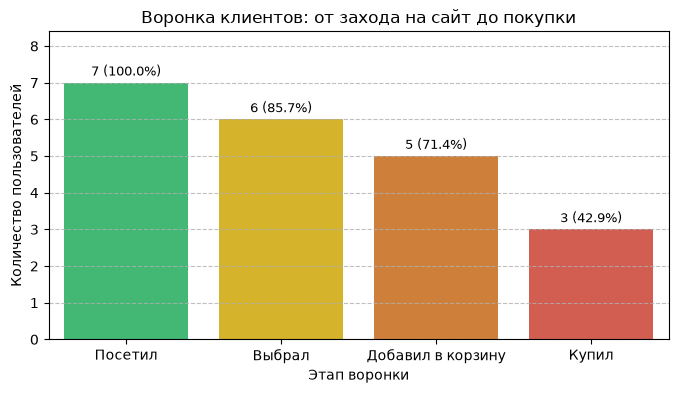

In [3]:
# 4. Строим столбчатую диаграмму: количество транзакций по клиентам и дням
plt.figure(figsize=(8,4)) #constrained_layot=True Подстройка изображения чтоб легенда за графиком влезла
# Задаем цвета от: зеленого к красному (4 цвета для 4 этапов)
colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c']
#Строим график с палитрой colors
ax=sns.barplot(data=df_funnel, x='step', y='count', palette=colors, hue='step', legend=False)
#Выводим значения и проценты над столбиками
for i, container in enumerate(ax.containers): #enumerate - счетчик, на каждом шаге цикла выдает пару: i, container.
    # Берем значение и процент для текущего столбика
    count_val = int(df_funnel['count'].iloc[i])
    percent_val= df_funnel['percent'].iloc[i]
    # Форматируем строку  "7 (100.0 %)"
    labels = [f"{count_val} ({percent_val}%)"]
    ax.bar_label(container, labels=labels,padding=3, fontsize=9)

plt.title('Воронка клиентов: от захода на сайт до покупки')
plt.xlabel('Этап воронки')
plt.ylabel('Количество пользователей')
plt.grid(axis='y',linestyle='--',alpha=0.8)
plt.ylim(0, df_funnel['count'].max() * 1.2)
plt.show()


Выводы по анализу воронки пользователей:

1. Только 42,9% посетителей сайта делают заказ.
2. Большинство пользователей больше всего теряется между корзиной (cart) и покупкой (purchase).